# NYU Depth V2: RGB, depth, class labels, instances

Reads [NYU Depth V2](https://cs.nyu.edu/~fergus/datasets/nyu_depth_v2.html)'s labeled subset (1449 RGB-D pairs with dense
per-pixel class and instance labels) directly from its own `nyu_depth_v2_labeled.mat` with `h5py` -- the file is
MATLAB v7.3 (HDF5), so `scipy.io.loadmat` can't read it. Needs `INSTALL.MD`'s NYU Depth V2 section run first, i.e.
`$HABITAT_DATA/nyu_depth_v2/nyu_depth_v2_labeled.mat`.

In [1]:
import os
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np

NYU_ROOT = Path("/home/hcrassou/habitat_data/data/nyu_depth_v2")
dataset = h5py.File(NYU_ROOT / "nyu_depth_v2_labeled.mat", "r")
list(dataset.keys())

['#refs#', '#subsystem#', 'accelData', 'depths', 'images', 'instances', 'labels', 'names', 'namesToIds', 'rawDepthFilenames', 'rawDepths', 'rawRgbFilenames', 'sceneTypes', 'scenes']

## Array layout

MATLAB stores arrays column-major, so `h5py` reads each array back transposed relative to its MATLAB shape:
`images` comes back `(N, 3, W, H)`, `depths`/`labels`/`instances` come back `(N, W, H)`. Transpose each frame to
`(H, W, [3])` before displaying. `labels` is 0 for unlabeled pixels, 1-894 for a NYU-specific per-pixel class id
(mapped to names via `names`/`namesToIds`); `instances` is 0 for unlabeled, else a per-image instance index that
restarts at 1 for every frame (not globally unique).

In [2]:
def read_names(dataset: h5py.File) -> list[str]:
    """dataset['names'] is a (1, C) array of HDF5 object references, each to a column of uint16 char codes."""
    return ["".join(chr(c) for c in dataset[ref][:, 0]) for ref in dataset["names"][0]]


NAMES = ["<unlabeled>"] + read_names(dataset)


def read_frame(dataset: h5py.File, index: int) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """(rgb, depth, labels, instances) for frame index, each transposed back to (H, W, ...)."""
    rgb = dataset["images"][index].transpose(2, 1, 0)
    depth = dataset["depths"][index].T
    labels = dataset["labels"][index].T
    instances = dataset["instances"][index].T
    return rgb, depth, labels, instances

## Drawing helpers

In [3]:
_PALETTE = np.array(
    [(0, 0, 0), (230, 25, 75), (60, 180, 75), (255, 225, 25), (0, 130, 200), (245, 130, 48),
     (145, 30, 180), (70, 240, 240), (240, 50, 230), (210, 245, 60), (250, 190, 212)],
    dtype=np.uint8,
)


def colorize_ids(ids: np.ndarray) -> np.ndarray:
    """ids (e.g. labels or instances) as an RGB image, 0 mapped to black, every other id cycled through the palette."""
    palette_index = np.where(ids == 0, 0, (ids - 1) % (len(_PALETTE) - 1) + 1)
    return _PALETTE[palette_index]


def colorize_depth(depth: np.ndarray) -> np.ndarray:
    normalized = (depth - depth.min()) / (depth.max() - depth.min() + 1e-8)
    return (plt.cm.viridis(normalized)[..., :3] * 255).astype(np.uint8)

## A few examples

In [4]:
def show_example(index: int) -> None:
    rgb, depth, labels, instances = read_frame(dataset, index)
    present_classes = ", ".join(NAMES[i] for i in np.unique(labels) if i > 0)

    panels = [
        ("RGB", rgb),
        ("depth", colorize_depth(depth)),
        ("class labels", colorize_ids(labels)),
        ("instances", colorize_ids(instances)),
    ]
    _, axes = plt.subplots(1, 4, figsize=(20, 5))
    for ax, (title, panel) in zip(axes, panels):
        ax.imshow(panel)
        ax.set_title(title)
        ax.axis("off")
    plt.suptitle(f"frame {index}: {present_classes}")
    plt.tight_layout()
    plt.show()

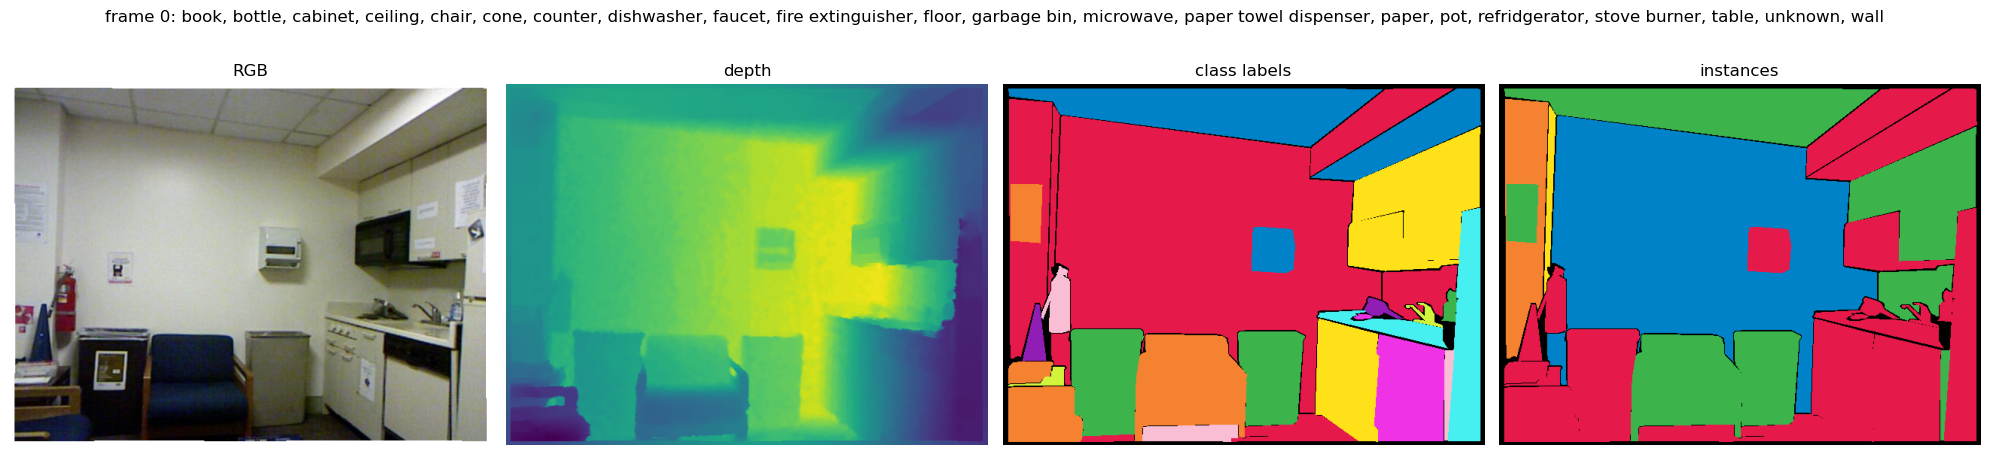

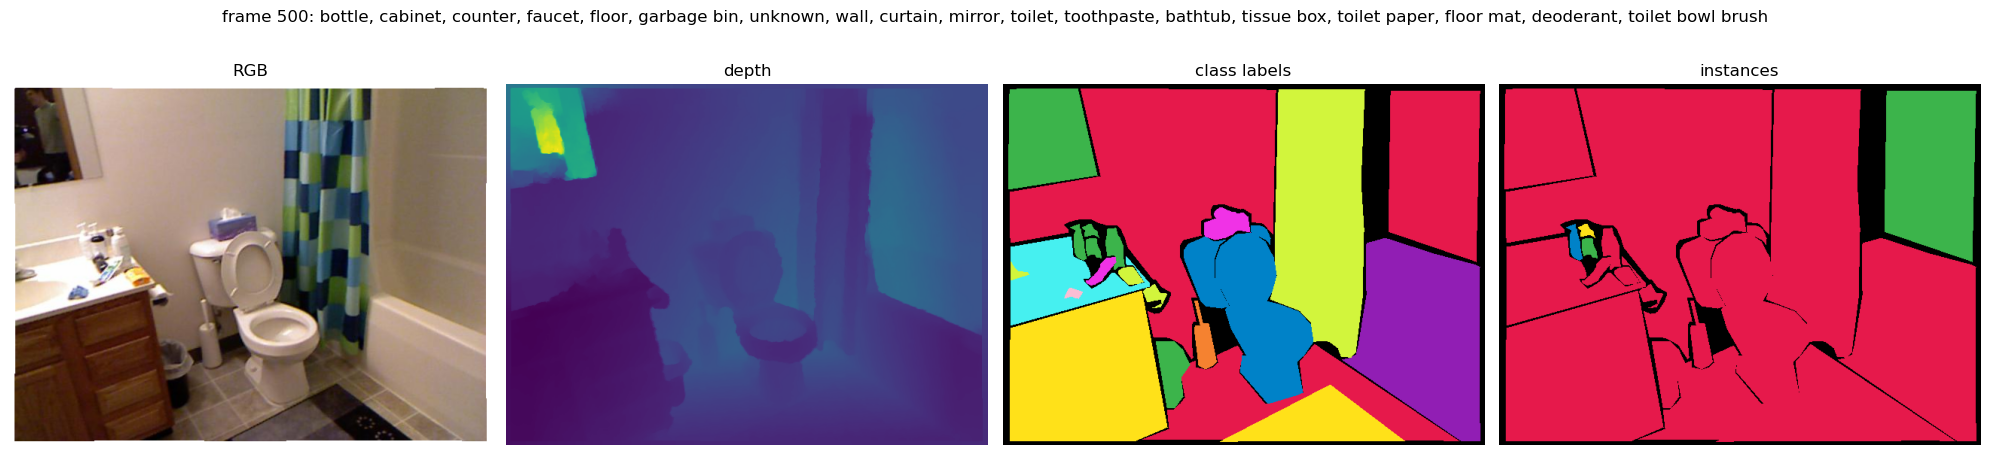

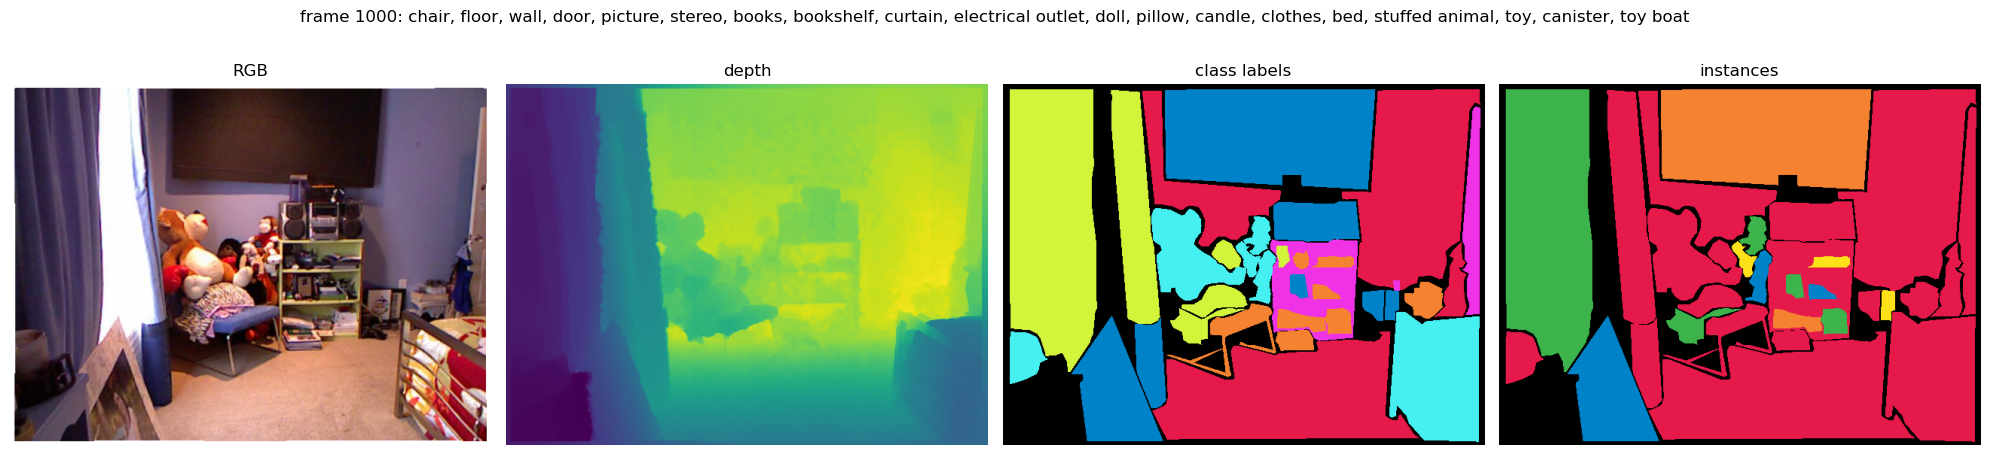

In [5]:
for index in [0, 500, 1000]:
    show_example(index)

## Register as a detectron2 dataset

Builds a `DatasetCatalog`/`MetadataCatalog` entry over every frame that has at least one labeled instance: each
connected `instances` id becomes one instance-segmentation annotation, classed by the majority `labels` value
under its mask (RLE-encoded, matching `common/utils/ground_truth_recovery.py`'s own `pycocotools` convention).
`file_name` is a synthetic per-frame locator, not a real path -- frames live inside the single `.mat` file, so
`DatasetCatalog.get` works but detectron2's default image-loading `DatasetMapper` won't resolve it.

In [6]:
from detectron2.data import DatasetCatalog, MetadataCatalog
from detectron2.structures import BoxMode
from pycocotools import mask as mask_util


def instance_annotations(labels: np.ndarray, instances: np.ndarray) -> list[dict]:
    annotations = []
    for instance_id in np.unique(instances):
        if instance_id == 0:
            continue
        mask = instances == instance_id
        label_counts = np.bincount(labels[mask], minlength=1)
        label_counts[0] = 0
        class_id = int(label_counts.argmax())
        if class_id == 0:
            continue
        rle = mask_util.encode(np.asfortranarray(mask.astype(np.uint8)))
        annotations.append({
            "bbox": mask_util.toBbox(rle).tolist(),
            "bbox_mode": BoxMode.XYWH_ABS,
            "segmentation": rle,
            "category_id": class_id - 1,
        })
    return annotations


def nyu_dataset_dicts() -> list[dict]:
    dataset_dicts = []
    for index in range(dataset["images"].shape[0]):
        _, _, labels, instances = read_frame(dataset, index)
        annotations = instance_annotations(labels.astype(np.int32), instances.astype(np.int32))
        if not annotations:
            continue
        dataset_dicts.append({
            "file_name": f"<nyu_depth_v2_labeled.mat>#images[{index}]",
            "image_id": index,
            "height": labels.shape[0],
            "width": labels.shape[1],
            "annotations": annotations,
        })
    return dataset_dicts


_nyu_dataset_dicts = nyu_dataset_dicts()
if "nyu_depth_v2" not in DatasetCatalog:
    DatasetCatalog.register("nyu_depth_v2", lambda: _nyu_dataset_dicts)
    MetadataCatalog.get("nyu_depth_v2").set(thing_classes=NAMES[1:])



In [7]:
print(len(DatasetCatalog.get("nyu_depth_v2")), len(NAMES[1:]))
print(sorted(NAMES[1:])[:100])

1449 894
['air conditioner', 'air duct', 'air vent', 'alarm', 'alarm clock', 'album', 'aluminium foil', 'american flag', 'antenna', 'apple', 'ashtray', 'avocado', 'baby chair', 'baby gate', 'back scrubber', 'backpack', 'bag', 'bag of bagels', 'bag of chips', 'bag of flour', 'bag of hot dog buns', 'bag of oreo', 'bagel', 'baking dish', 'ball', 'balloon', 'banana', 'banana peel', 'banister', 'bar', 'bar of soap', 'barrel', 'baseball', 'basket', 'basketball', 'basketball hoop', 'bassinet', 'bathtub', 'bean bag', 'bed', 'bed sheets', 'bedding package', 'beeper', 'belt', 'bench', 'bicycle', 'bicycle helmet', 'bin', 'binder', 'blackboard', 'blanket', 'blender', 'blinds', 'board', 'book', 'book holder', 'bookend', 'bookrack', 'books', 'bookshelf', 'boomerang', 'bottle', 'bottle of comet', 'bottle of contact lens solution', 'bottle of hand wash liquid', 'bottle of ketchup', 'bottle of liquid', 'bottle of listerine', 'bottle of perfume', 'bottle of soap', 'bowl', 'box', 'box of paper', 'box of 

## Merge semantic synonyms (pre-count)

String-level normalization only (lowercase, flatten `_`/`-`/whitespace, strip a naive trailing plural) -- catches
spelling variants like `book`/`books`, not different-looking synonyms. Applied before counting, so the histogram
below is grouped, not raw.

In [8]:
from collections import defaultdict


def canonicalize(name: str) -> str:
    """Flattened, lowercased name with a naive trailing plural stripped -- merges 'book'/'books' without touching
    words that already end in 's' (e.g. 'glass')."""
    normalized = " ".join(name.lower().replace("_", " ").replace("-", " ").split())
    return normalized[:-1] if normalized.endswith("s") and not normalized.endswith("ss") else normalized


def merge_synonym_counts(raw_counts: dict[str, int]) -> tuple[dict[str, int], list[list[str]]]:
    """Groups raw_counts' keys by canonicalize(), keeping the most frequent raw spelling per group as its
    representative and summing the group's counts under it. merged_groups lists only groups with more than
    one raw spelling, for auditing."""
    groups = defaultdict(list)
    for name in raw_counts:
        groups[canonicalize(name)].append(name)

    merged_counts, merged_groups = {}, []
    for group in groups.values():
        representative = max(group, key=lambda name: raw_counts[name])
        merged_counts[representative] = sum(raw_counts[name] for name in group)
        if len(group) > 1:
            merged_groups.append(sorted(group, key=lambda name: -raw_counts[name]))
    return merged_counts, merged_groups

## Class frequency

Exhaustive per-class instance count from the registered dataset (`_nyu_dataset_dicts`), log-scale x. Most of
`NAMES`' 894 raw labels never win an instance's majority vote (fine-grained sub-parts like `tabletop` get folded
into their parent object's mask), so only the classes that actually ended up registered as an instance appear
here -- not all 894.

merged 4 raw classnames into 2 groups, e.g.:
  books + book
  paper + papers


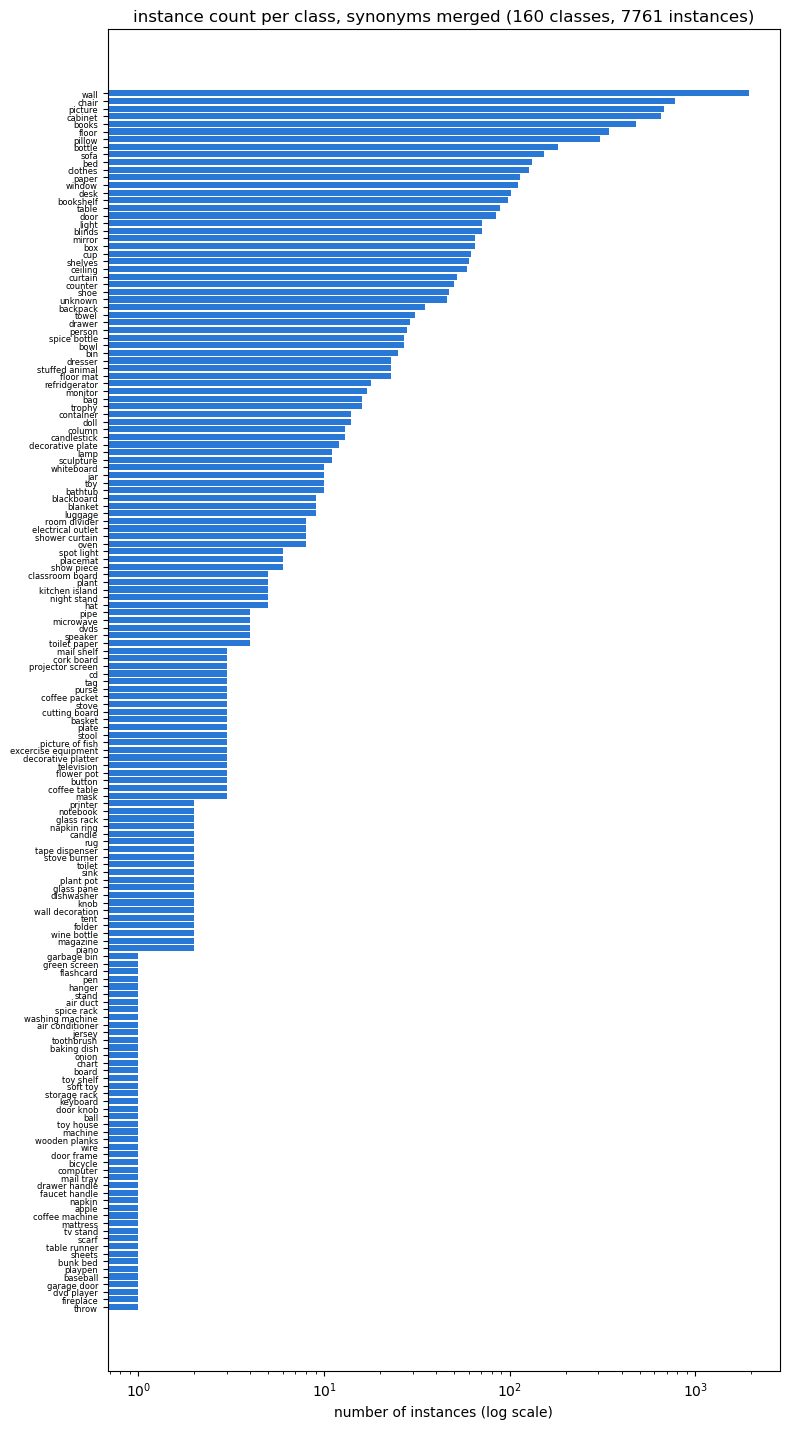

In [9]:
from collections import Counter

nyu_classes = NAMES[1:]
instance_counts = Counter(ann["category_id"] for record in _nyu_dataset_dicts for ann in record["annotations"])
raw_counts = {nyu_classes[i]: n for i, n in instance_counts.items()}
merged_counts, merged_groups = merge_synonym_counts(raw_counts)
print(f"merged {sum(len(g) for g in merged_groups)} raw classnames into {len(merged_groups)} groups, e.g.:")
for group in sorted(merged_groups, key=lambda g: -sum(raw_counts[n] for n in g))[:15]:
    print(" ", " + ".join(group))

counts_sorted = sorted(merged_counts.items(), key=lambda x: -x[1])
names, counts = zip(*counts_sorted)

fig, ax = plt.subplots(figsize=(8, max(6, len(names) * 0.09)))
ax.barh(range(len(names)), counts, color="#2a78d6")
ax.set_yticks(range(len(names)))
ax.set_yticklabels(names, fontsize=6)
ax.invert_yaxis()
ax.set_xscale("log")
ax.set_xlabel("number of instances (log scale)")
ax.set_title(f"instance count per class, synonyms merged ({len(names)} classes, {sum(counts)} instances)")
plt.tight_layout()
plt.show()

In [10]:
counts_sorted

[('wall', 1955), ('chair', 779), ('picture', 677), ('cabinet', 651), ('books', 478), ('floor', 342), ('pillow', 307), ('bottle', 181), ('sofa', 153), ('bed', 131), ('clothes', 127), ('paper', 114), ('window', 111), ('desk', 101), ('bookshelf', 98), ('table', 89), ('door', 84), ('light', 71), ('blinds', 71), ('mirror', 65), ('box', 65), ('cup', 62), ('shelves', 60), ('ceiling', 59), ('curtain', 52), ('counter', 50), ('shoe', 47), ('unknown', 46), ('backpack', 35), ('towel', 31), ('drawer', 29), ('person', 28), ('spice bottle', 27), ('bowl', 27), ('bin', 25), ('dresser', 23), ('stuffed animal', 23), ('floor mat', 23), ('refridgerator', 18), ('monitor', 17), ('bag', 16), ('trophy', 16), ('container', 14), ('doll', 14), ('column', 13), ('candlestick', 13), ('decorative plate', 12), ('lamp', 11), ('sculpture', 11), ('whiteboard', 10), ('jar', 10), ('toy', 10), ('bathtub', 10), ('blackboard', 9), ('blanket', 9), ('luggage', 9), ('room divider', 8), ('electrical outlet', 8), ('shower curtain'

In [11]:
frequent_classes_nyu = sorted([n for n, c in counts_sorted if c > 10])
print(len(frequent_classes_nyu))
print(frequent_classes_nyu)

49
['backpack', 'bag', 'bed', 'bin', 'blinds', 'books', 'bookshelf', 'bottle', 'bowl', 'box', 'cabinet', 'candlestick', 'ceiling', 'chair', 'clothes', 'column', 'container', 'counter', 'cup', 'curtain', 'decorative plate', 'desk', 'doll', 'door', 'drawer', 'dresser', 'floor', 'floor mat', 'lamp', 'light', 'mirror', 'monitor', 'paper', 'person', 'picture', 'pillow', 'refridgerator', 'sculpture', 'shelves', 'shoe', 'sofa', 'spice bottle', 'stuffed animal', 'table', 'towel', 'trophy', 'unknown', 'wall', 'window']
